# Part 2: Convolutional neural networks

Data preparation, experiments (network size, dropout), extras (data augmentation, batch normalization), cross-validation, evaluation per letter, visualisation of what the network sees, and export + reload of the best network.

## 1. Data preparation

The letter is the first part of the file name. Images are pasted on white paper (the PNGs are transparent), converted to grayscale and inverted, so the ink is 1 and the background is 0.

In [34]:
from pathlib import Path
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import to_categorical

IMAGE_DIR = Path("../data/letters")     
IMG_SIZE = 128                     
GROUP_SPLIT = True                
SEED = 42

files = sorted(IMAGE_DIR.glob("*.png"))
parts = [f.stem.split("_") for f in files]
letters = [p[0] for p in parts]                                  
sessions = np.array(["_".join(p[1:3]) for p in parts])         
CLASSES = sorted(set(letters))

print(len(files), "images,", len(CLASSES), "classes:", CLASSES)
print(len(set(sessions)), "distinct date/time stamps")

def load_image(path):
    im = Image.open(path).convert("RGBA")
    paper = Image.new("RGBA", im.size, (255, 255, 255, 255))
    im = Image.alpha_composite(paper, im).convert("L")          
    
    if im.size != (IMG_SIZE, IMG_SIZE):
        im = im.resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS)
    
    return 1.0 - np.asarray(im, dtype=np.float32) / 255.0        

X = np.stack([load_image(f) for f in files])[..., None]          
y = np.array([CLASSES.index(l) for l in letters])

1286 images, 11 classes: ['crbvb', 'erb', 'glagoli', 'ju', 'myslite', 'rbci', 'sa', 'slovo', 'sta', 'tvrbdo', 'vede']
178 distinct date/time stamps


All images with the same date/time stamp stay in the same part (train, validation or test). Images from one stamp were probably drawn by the same person in one go, so they look alike; if they were spread over train and test, the test score would be too optimistic.

In [35]:
if GROUP_SPLIT:  
    folds = [te for _, te in StratifiedGroupKFold(7, shuffle=True, random_state=SEED).split(np.zeros(len(y)), y, sessions)]
    test_idx, val_idx, train_idx = folds[0], folds[1], np.concatenate(folds[2:])
else:
    train_idx, rest = train_test_split(np.arange(len(y)), test_size=0.30, stratify=y, random_state=SEED)
    val_idx, test_idx = train_test_split(rest, test_size=0.50, stratify=y[rest], random_state=SEED)

shared = set(sessions[train_idx]) & (set(sessions[val_idx]) | set(sessions[test_idx]))
print("time stamps shared between train and validation/test:", len(shared))

count = lambda idx: np.bincount(y[idx], minlength=len(CLASSES))
print(pd.DataFrame({"letter": CLASSES, "train": count(train_idx), "validation": count(val_idx), "test": count(test_idx)}).to_string(index=False))

N_CLASSES = len(CLASSES)
X_train, y_train, X_val, y_val, X_test, y_test = X[train_idx], y[train_idx], X[val_idx], y[val_idx], X[test_idx], y[test_idx]
Y_train, Y_val, Y_test = (to_categorical(a, N_CLASSES) for a in (y_train, y_val, y_test))

TEST_FILE = Path("cnn_test_files.csv")                       # list of the test images, used by the reload cell
pd.DataFrame({"file": [files[i].name for i in test_idx], "letter": [letters[i] for i in test_idx]}).to_csv(TEST_FILE, index=False)

time stamps shared between train and validation/test: 0
 letter  train  validation  test
  crbvb     55          13    13
    erb    103          23    18
glagoli     67          16    15
     ju    107          18    17
myslite     63          13    12
   rbci     87          16    21
     sa     97          17    23
  slovo     70          12    12
    sta     70          17    16
 tvrbdo     95          17    17
   vede    110          18    18


## 2. Experiments

Early stopping watches the validation accuracy (patience 15, at most 150 epochs). A first version watched the validation loss; see 3.1 for why that did not work here.

In [36]:
MAX_EPOCHS, PATIENCE, BATCH = 150, 15, 32
RESULTS, MODELS = Path("results_cnn"), Path("models_cnn")
RESULTS.mkdir(exist_ok=True); MODELS.mkdir(exist_ok=True)

augmentation = keras.Sequential([                           
    layers.RandomRotation(0.03, fill_mode="constant"),
    layers.RandomTranslation(0.08, 0.08, fill_mode="constant"),
    layers.RandomZoom(0.1, fill_mode="constant"),
], name="augmentation")                                      # no flips: a mirrored letter is a different letter

def build_cnn(filters, dense=64, dropout=0.0, gap=False, augment=False, batchnorm=False):
    """filters: one convolution (3x3) + max-pooling per entry; gap=True uses global average pooling instead of Flatten."""
    stack = [keras.Input(X_train.shape[1:])]
    if augment:
        stack.append(augmentation)
    
    for f in filters:
        if batchnorm:                                        # convolution -> normalize -> activation
            stack += [layers.Conv2D(f, 3, padding="same", use_bias=False), layers.BatchNormalization(), layers.Activation("relu")]
        else:
            stack.append(layers.Conv2D(f, 3, padding="same", activation="relu"))
        stack.append(layers.MaxPooling2D())
    
    stack.append(layers.GlobalAveragePooling2D() if gap else layers.Flatten())
    
    if dense:
        stack.append(layers.Dense(dense, activation="relu"))
    if dropout:
        stack.append(layers.Dropout(dropout))
    
    stack.append(layers.Dense(N_CLASSES, activation="softmax"))
    
    model = keras.Sequential(stack)
    model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    
    return model

In [37]:
def report(r):
    print(f"{r['name']:30s} params={r['params']:>9,}  epochs={r['epochs_run']:3d} (best {r['best_epoch']:3d})  {r['seconds']:5.0f}s  "
          f"val_acc={r['val_acc']:.3f}  test_acc={r['test_acc']:.3f}")

def run_experiment(name, filters, dense=64, gap=False, dropout=0.0, augment=False, batchnorm=False, force=False):
    path = RESULTS / f"{name}.json"
    if path.exists() and not force:                              # finished runs are loaded, not repeated
        result = json.loads(path.read_text())
        report(result)
        return result
    
    keras.utils.set_random_seed(SEED)
    
    model = build_cnn(filters, dense, dropout, gap, augment, batchnorm)
    stop = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=PATIENCE, restore_best_weights=True)
    t = time.perf_counter()
    
    h = model.fit(X_train, Y_train, validation_data=(X_val, Y_val), epochs=MAX_EPOCHS,
                  batch_size=BATCH, callbacks=[stop], verbose=0)
    
    seconds = time.perf_counter() - t
    test_loss, test_acc = model.evaluate(X_test, Y_test, batch_size=64, verbose=0)
    pred = model.predict(X_test, batch_size=64, verbose=0).argmax(1)
    recall = [float((pred[y_test == c] == c).mean()) for c in range(N_CLASSES)]
    hist = {k: [float(v) for v in vals] for k, vals in h.history.items()}
    
    best = int(np.argmax(hist["val_accuracy"]))                  # the epoch early stopping restored
    result = dict(name=name, arch=name.rsplit("_d", 1)[0], filters=filters, dense=dense, gap=gap, dropout=dropout,
                  augment=augment, batchnorm=batchnorm, params=int(model.count_params()),
                  epochs_run=len(hist["loss"]), best_epoch=best + 1, seconds=round(seconds, 1),
                  val_acc=hist["val_accuracy"][best], val_loss=hist["val_loss"][best],
                  test_acc=float(test_acc), test_loss=float(test_loss), recall=recall, history=hist)
    model.save(MODELS / f"{name}.keras")
    
    path.write_text(json.dumps(result))
    report(result)
    return result

In [38]:
ARCH = {                                   
    "c16-32_fc64":       ([16, 32],       64,  False),
    "c32-64_fc128":      ([32, 64],       128, False),
    "c16-32-64_fc128":   ([16, 32, 64],   128, False),
    "c32-64-128_fc128":  ([32, 64, 128],  128, False),
    "c32-64_gap":        ([32, 64],       0,   True),
    "c32-64-128_gap":    ([32, 64, 128],  0,   True),
}
EXPERIMENTS  = [(f"{a}_d0.0", *ARCH[a], 0.0) for a in ARCH]                                       # sizes, no dropout
EXPERIMENTS += [(f"{a}_d{p}", *ARCH[a], p) for a in ("c32-64_fc128", "c32-64-128_gap") for p in (0.3, 0.5)]  # dropout
print(len(EXPERIMENTS), "experiments")

for exp in EXPERIMENTS:          
    run_experiment(*exp)

10 experiments
c16-32_fc64_d0.0               params=2,102,731  epochs= 19 (best   4)     39s  val_acc=0.772  test_acc=0.819
c32-64_fc128_d0.0              params=8,408,971  epochs= 20 (best   5)    107s  val_acc=0.767  test_acc=0.846
c16-32-64_fc128_d0.0           params=2,121,995  epochs= 19 (best   4)     47s  val_acc=0.861  test_acc=0.857
c32-64-128_fc128_d0.0          params=4,288,523  epochs= 20 (best   5)    148s  val_acc=0.839  test_acc=0.852
c32-64_gap_d0.0                params=   19,531  epochs= 91 (best  76)    428s  val_acc=0.650  test_acc=0.676
c32-64-128_gap_d0.0            params=   94,091  epochs= 92 (best  77)    585s  val_acc=0.828  test_acc=0.912
c32-64_fc128_d0.3              params=8,408,971  epochs= 33 (best  18)    198s  val_acc=0.833  test_acc=0.863
c32-64_fc128_d0.5              params=8,408,971  epochs= 36 (best  21)    224s  val_acc=0.839  test_acc=0.852
c32-64-128_gap_d0.3            params=   94,091  epochs=122 (best 107)    794s  val_acc=0.861  test_acc=0

## 3. Results

In [39]:
def summary(folder=RESULTS):
    rows = [json.loads(p.read_text()) for p in folder.glob("*.json")]
    df = pd.DataFrame(rows).drop(columns=["history", "recall"], errors="ignore")
    df["filters"] = df["filters"].astype(str)
    return df.sort_values(["val_acc", "val_loss"], ascending=[False, True]).reset_index(drop=True)

def plot_run(name, folder=RESULTS):
    r = json.loads((folder / f"{name}.json").read_text()); h = r["history"]; ep = range(1, len(h["loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
    for a, key, title in ((ax[0], "accuracy", "accuracy"), (ax[1], "loss", "cross-entropy loss")):
        a.plot(ep, h[key], label="train"); a.plot(ep, h["val_" + key], label="validation")
        a.axvline(r["best_epoch"], color="gray", ls=":", label=f"best epoch ({r['best_epoch']})")
        a.set_xlabel("epoch"); a.set_title(title); a.legend()
    fig.suptitle(f"{name}   (test accuracy {r['test_acc']:.3f})"); fig.tight_layout(); plt.show()

summary()

,name,arch,filters,dense,gap,dropout,augment,batchnorm,params,epochs_run,best_epoch,seconds,val_acc,val_loss,test_acc,test_loss
0,c16-32-64_fc128_d0.0_aug_bn,c16-32-64_fc128,"[16, 32, 64]",128,False,0.0,True,True,2122331,72,57,605.2,0.977778,0.255216,0.978022,0.074457
1,c16-32-64_fc128_d0.0_aug,c16-32-64_fc128,"[16, 32, 64]",128,False,0.0,True,False,2121995,31,16,81.6,0.961111,0.130823,0.978022,0.058480
2,c32-64-128_gap_d0.5_aug,c32-64-128_gap,"[32, 64, 128]",0,True,0.5,True,False,94091,142,127,1232.5,0.922222,0.298374,0.972527,0.067631
3,c32-64-128_gap_d0.5,c32-64-128_gap,"[32, 64, 128]",0,True,0.5,False,False,94091,114,99,809.7,0.883333,0.488993,0.972527,0.094588
4,c32-64-128_gap_d0.3,c32-64-128_gap,"[32, 64, 128]",0,True,0.3,False,False,94091,122,107,793.9,0.861111,0.546703,0.978022,0.077841
5,c16-32-64_fc128_d0.0,c16-32-64_fc128,"[16, 32, 64]",128,False,0.0,False,False,2121995,19,4,47.1,0.861111,0.697045,0.857143,0.812720
6,c32-64-128_fc128_d0.0,c32-64-128_fc128,"[32, 64, 128]",128,False,0.0,False,False,4288523,20,5,148.2,0.838889,0.890000,0.851648,0.738126
7,c32-64_fc128_d0.5,c32-64_fc128,"[32, 64]",128,False,0.5,False,False,8408971,36,21,223.6,0.838889,1.009914,0.851648,0.751825
8,c32-64_fc128_d0.3,c32-64_fc128,"[32, 64]",128,False,0.3,False,False,8408971,33,18,198.1,0.833333,1.053987,0.862637,0.861598
9,c32-64-128_gap_d0.0,c32-64-128_gap,"[32, 64, 128]",0,True,0.0,False,False,94091,92,77,585.0,0.827778,0.735559,0.912088,0.224321


### 3.1 First version: early stopping on the validation loss

The first grid used `monitor="val_loss"`, patience 6 and at most 40 epochs (results kept in `results_cnn_valloss/`). For the Flatten networks the lowest validation loss was often in epoch 1, while the validation accuracy was still improving for a few more epochs, so early stopping restored an almost untrained network.

In [40]:
OLD = Path("results_cnn_valloss")
summary(OLD)[["name", "params", "epochs_run", "best_epoch", "val_acc", "val_loss", "test_acc"]]

,name,params,epochs_run,best_epoch,val_acc,val_loss,test_acc
0,c16-32-64_fc128_d0.0,2121995,10,4,0.861111,0.697045,0.857143
1,c32-64_fc128_d0.3,8408971,14,8,0.822222,0.833318,0.879121
2,c32-64_fc128_d0.5,8408971,11,5,0.783333,0.841838,0.818681
3,c32-64-128_fc128_d0.0,4288523,7,1,0.761111,0.690984,0.824176
4,c32-64-128_gap_d0.3,94091,40,36,0.755556,0.719565,0.851648
5,c32-64-128_gap_d0.5,94091,40,40,0.738889,0.755113,0.868132
6,c32-64-128_gap_d0.0,94091,30,24,0.733333,0.856519,0.835165
7,c32-64_fc128_d0.0,8408971,7,1,0.722222,0.932921,0.791209
8,c16-32_fc64_d0.0,2102731,7,1,0.700000,1.071397,0.769231
9,c32-64_gap_d0.0,19531,40,40,0.533333,1.309166,0.571429


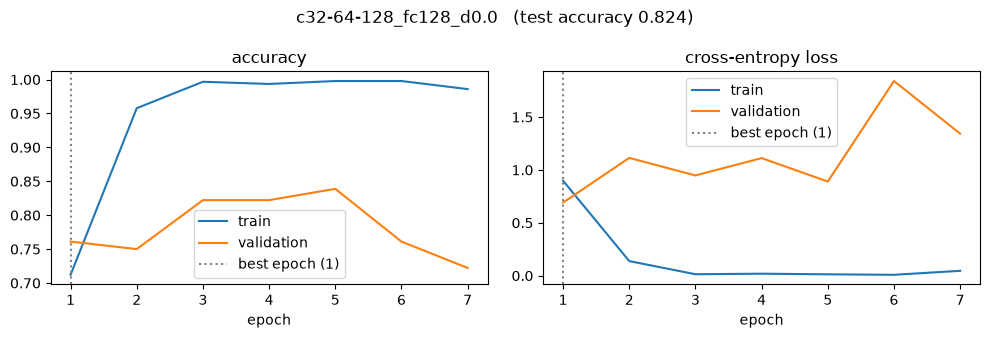

In [41]:
plot_run("c32-64-128_fc128_d0.0", OLD)

**Observations first version:** In the first version the validation loss is lowest in epoch 1 (0.69) and then goes up, while the validation accuracy still improves until epoch 5 (0.84). So early stopping on the loss restored the weights from epoch 1, when the network had hardly learned anything (0.76). 

The reason is that the training accuracy is already ~1.0 after 3 epochs: the network memorises the training images and becomes over-confident. The few validation images it gets wrong get almost 0 probability for the correct letter, and this makes the cross-entropy explode, even while more images are classified correctly. That is why the second version watches the validation accuracy (patience 15, max 150 epochs). For the Flatten networks this gave the same or a better test accuracy (e.g. c32-64-128_fc128 0.824 -> 0.852), and the GAP networks could finally train long enough.

### 3.2 Network size (no dropout)

Convolution layers with 3x3 filters + max-pooling, then either Flatten + a dense layer (`fc`) or global average pooling (`gap`, no dense layer). The number of filters doubles in every layer.

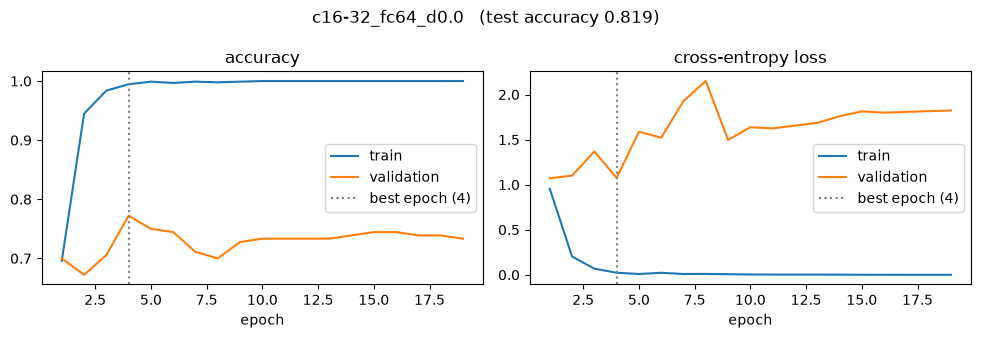

In [42]:
plot_run("c16-32_fc64_d0.0")

**Observations `c16-32_fc64_d0.0`:** The training accuracy goes to 1.0 in about 3 epochs, while the validation accuracy stays between 0.70 and 0.77 and the validation loss keeps going up. This is clear overfitting: the network has 2.1M weights (almost all in the dense layer after Flatten: 32x32x32 = 32,768 inputs x 64 neurons) for only ~920 training images, so it can simply memorise them. 

Best validation accuracy at epoch 4 (0.772), test accuracy 0.819.

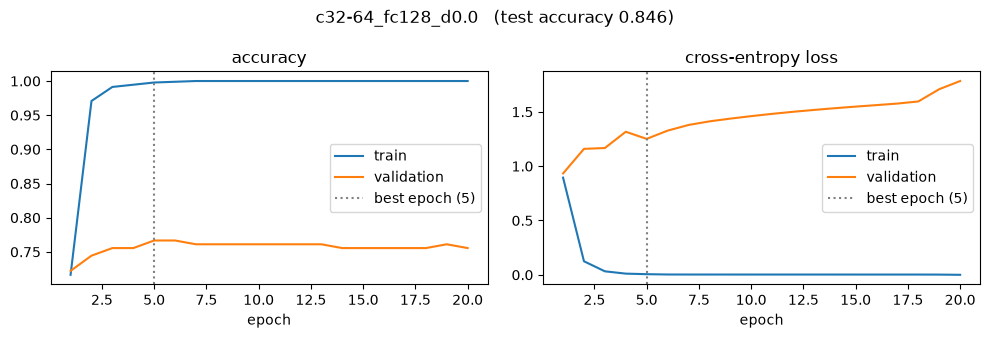

In [43]:
plot_run("c32-64_fc128_d0.0")

**Observations `c32-64_fc128_d0.0`:** Same behaviour as c16-32_fc64, but even more extreme: train 1.0 after 3 epochs, validation flat at ~0.76 and the validation loss rises steadily. 

With twice as many filters and 128 neurons the network has 8.4M weights (32x32x64 = 65,536 inputs x 128), so more weights did not help at all: validation 0.767, test 0.846.

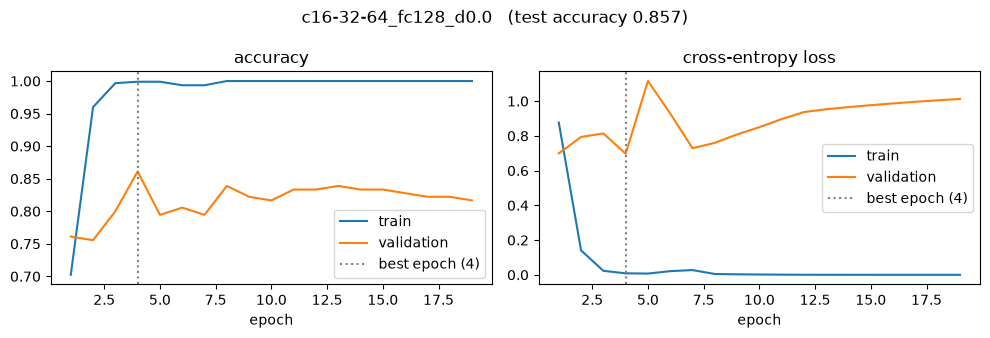

In [44]:
plot_run("c16-32-64_fc128_d0.0")

**Observations `c16-32-64_fc128_d0.0`:** Adding a third convolutional layer helps: validation 0.861 (vs 0.772 and 0.767 with 2 conv layers) and test 0.857. The extra max-pooling makes the image smaller (16x16x64 before Flatten), so the dense layer has fewer weights (2.1M), and the third layer can combine the simple features of the first layers into bigger parts of the letter. It still overfits in the same way: train 1.0 after 3 epochs and a rising validation loss.

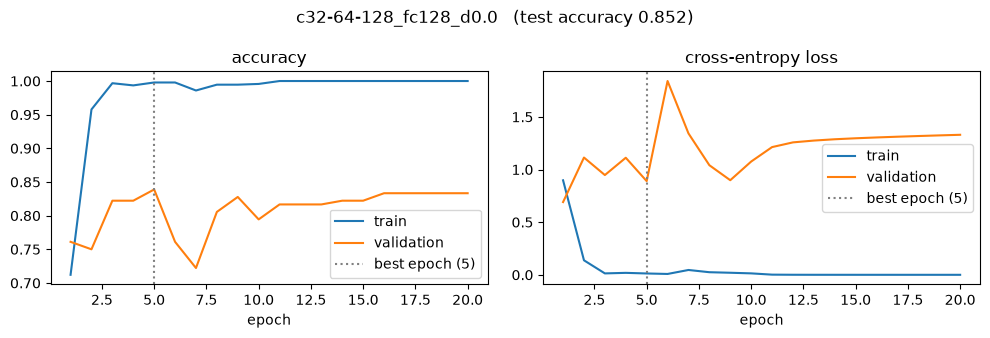

In [45]:
plot_run("c32-64-128_fc128_d0.0")

**Observations `c32-64-128_fc128_d0.0`:** With more filters per layer (32-64-128 instead of 16-32-64) the result is not better: validation 0.839, test 0.852, and the validation curves jump up and down more (0.72-0.84). The network has twice as many weights (4.3M), but the problem is the same: it memorises the training set within 3 epochs. So for the Flatten networks the number of layers mattered more than the number of filters.

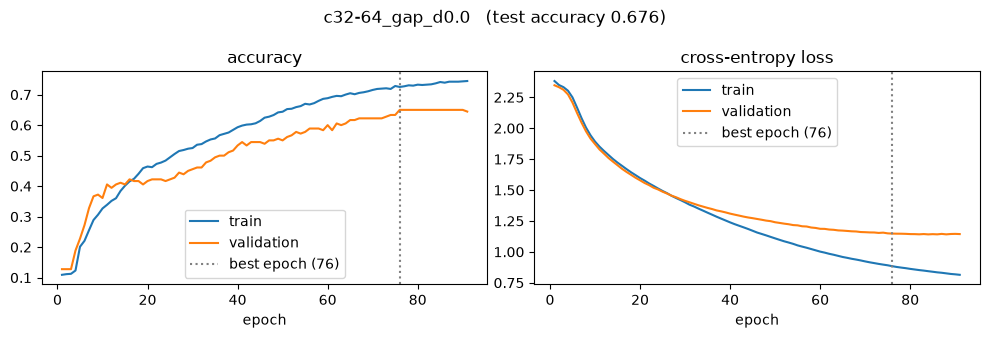

In [46]:
plot_run("c32-64_gap_d0.0")

**Observations `c32-64_gap_d0.0`:** This network looks completely different: it has only 19,531 weights, because global average pooling replaces the big dense layer (it takes the average of each of the 64 feature maps). It learns slowly and steadily: train and validation go up together, and the loss curves are almost on top of each other for 30 epochs. But it is the worst network (validation 0.650, test 0.676), so it is underfitting. With only 2 conv layers each feature only "sees" a small part of the 128x128 image, and the averaging throws away where in the image a feature was, so it cannot recognise the shape of the letter well.

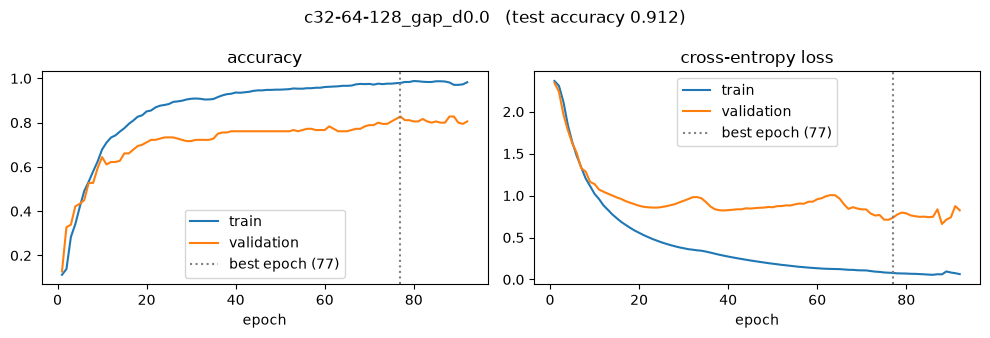

In [47]:
plot_run("c32-64-128_gap_d0.0")

**Observations `c32-64-128_gap_d0.0`:** With a third conv layer the GAP network becomes much better: validation 0.828, test 0.912 (with only 94,091 weights, about 22x fewer than c16-32-64_fc128). The third layer sees bigger parts of the letter before the averaging. Up to ~20 epochs train and validation are equal; after that the training accuracy keeps going up to ~0.98 while validation stays around 0.80, so it starts to overfit, but much slower and less than the Flatten networks. It needed 77 epochs, so with the old maximum of 40 epochs it was stopped too early. The big gap between validation (0.828) and test (0.912) shows how noisy the small validation and test sets are.

### 3.3 Dropout

Dropout before the output layer; the versions without dropout are in 3.2.

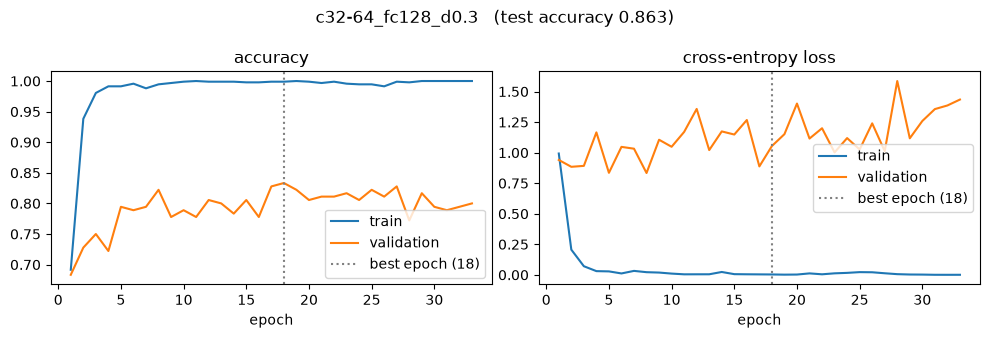

In [48]:
plot_run("c32-64_fc128_d0.3")

**Observations `c32-64_fc128_d0.3`:** With 30% dropout the training accuracy still reaches 1.0 within 4 epochs, so the network still memorises the training set, but validation improves from 0.767 to 0.833 (test 0.863) and it keeps learning for longer (best epoch 18 instead of 5). The validation curves jump up and down a lot (0.78-0.83 per epoch), which is normal with only 180 validation images (1 image = 0.55%).

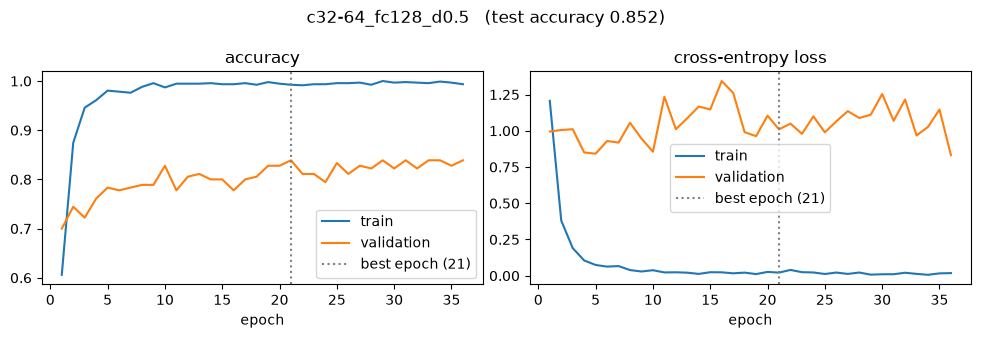

In [49]:
plot_run("c32-64_fc128_d0.5")

**Observations `c32-64_fc128_d0.5`:** With 50% dropout the result is about the same as with 30% (validation 0.839, test 0.852). Training accuracy is slightly lower in the first epochs but still close to 1.0, so even half of the neurons is enough to memorise ~920 images. Dropout helps a little for the Flatten network, but it does not solve the overfitting, because the 8.4M weights before the dropout layer can still memorise the images.

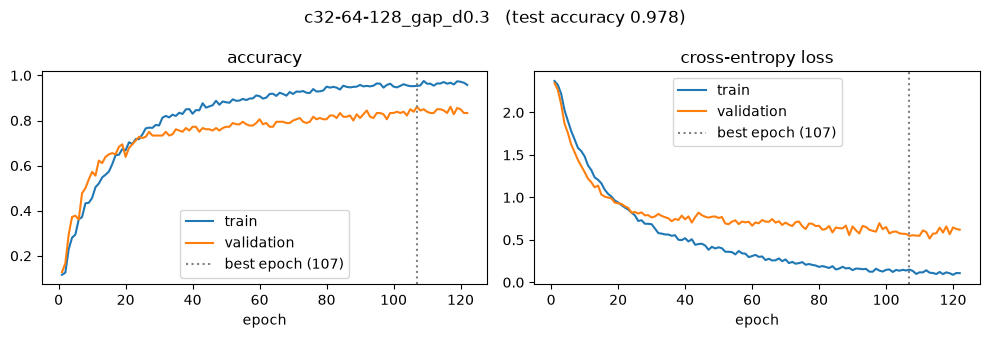

In [50]:
plot_run("c32-64-128_gap_d0.3")

**Observations `c32-64-128_gap_d0.3`:** Here dropout works much better: the gap between train and validation is smaller than without dropout, and the validation accuracy keeps going up until epoch 107 (0.861; without dropout 0.828). The test accuracy is 0.978, the best of the grid. Training takes much longer (122 epochs), because dropout makes learning slower.

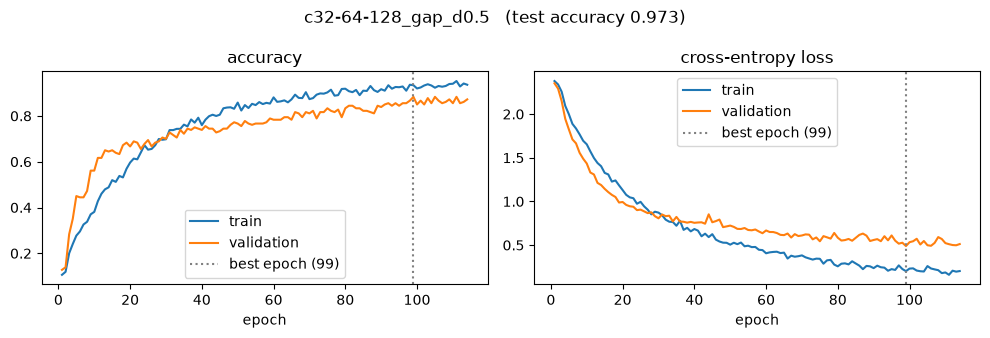

In [51]:
plot_run("c32-64-128_gap_d0.5")

**Observations `c32-64-128_gap_d0.5`:** With 50% dropout the training accuracy is below the validation for the first ~30 epochs (dropout is only active during training), and the two curves stay closer together than with 30%. This is the best network of the grid on validation (0.883, test 0.973). For the GAP network, which has few weights and overfits slowly, dropout is a good regularizer; for the Flatten networks it was not enough.

## 4. Data augmentation and batch normalization
**Data augmentation** makes new training images from the existing ones by small random changes (rotation up to ~11 degrees, shift up to 8%, zoom up to 10%). Every epoch the network sees a slightly different version of each letter, so it cannot simply memorise the ~900 training images and has to learn the shape. The changes are small enough that the letter stays the same; flipping is not used because a mirrored letter is a different letter. The augmentation layers are part of the model but only work during training.

**Batch normalization** normalizes the output of each convolution per batch (mean 0, standard deviation 1) and then lets the network learn a scale and shift. This keeps the values in a stable range, so training is faster and less sensitive to the learning rate, and the noise of the batch statistics also has a small regularizing effect.

Both are tested on the two best architectures from section 3.

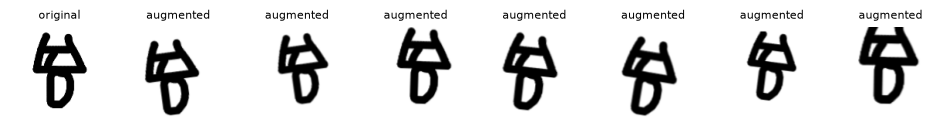

In [52]:
sample = X_train[:1]
fig, axes = plt.subplots(1, 8, figsize=(12, 1.9))
axes[0].imshow(sample[0, ..., 0], cmap="gray_r"); axes[0].set_title("original", fontsize=8)
for a in axes[1:]:
    a.imshow(augmentation(sample, training=True)[0, ..., 0], cmap="gray_r"); a.set_title("augmented", fontsize=8)
for a in axes: a.axis("off")
plt.show()

In [53]:
grid = summary()
grid = grid[~grid["augment"].astype(bool) & ~grid["batchnorm"].astype(bool)]   # only the runs of section 3
top2 = grid.drop_duplicates("arch").head(2)                    # best run of the two best architectures
EXTRAS = []
for i, (_, r) in enumerate(top2.iterrows()):
    variants = [("aug", True, False), ("bn", False, True), ("aug_bn", True, True)] if i == 0 else [("aug_bn", True, True)]
    for tag, aug, bn in variants:
        EXTRAS.append((f"{r['name']}_{tag}", json.loads(r["filters"]), int(r["dense"]), bool(r["gap"]), float(r["dropout"]), aug, bn))
print("extras on:", list(top2["name"]))

extra_results = [run_experiment(*e) for e in EXTRAS]

extras on: ['c32-64-128_gap_d0.5', 'c16-32-64_fc128_d0.0']
c32-64-128_gap_d0.5_aug        params=   94,091  epochs=142 (best 127)   1232s  val_acc=0.922  test_acc=0.973
c32-64-128_gap_d0.5_bn         params=   94,763  epochs= 51 (best  36)    943s  val_acc=0.733  test_acc=0.819
c32-64-128_gap_d0.5_aug_bn     params=   94,763  epochs= 46 (best  31)    987s  val_acc=0.756  test_acc=0.835
c16-32-64_fc128_d0.0_aug_bn    params=2,122,331  epochs= 72 (best  57)    605s  val_acc=0.978  test_acc=0.978


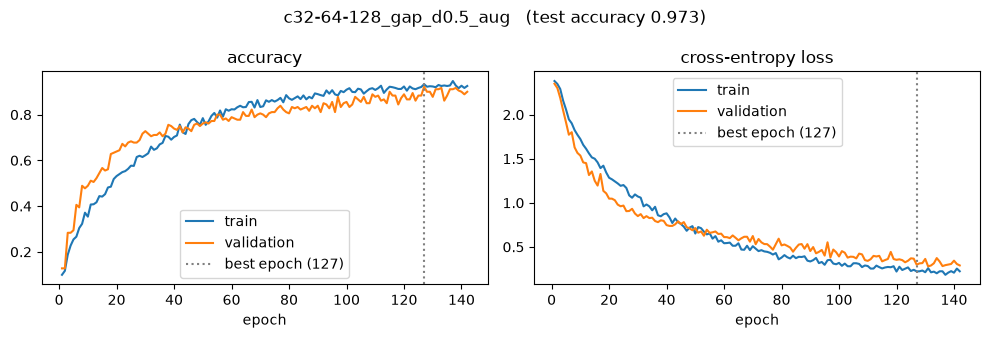

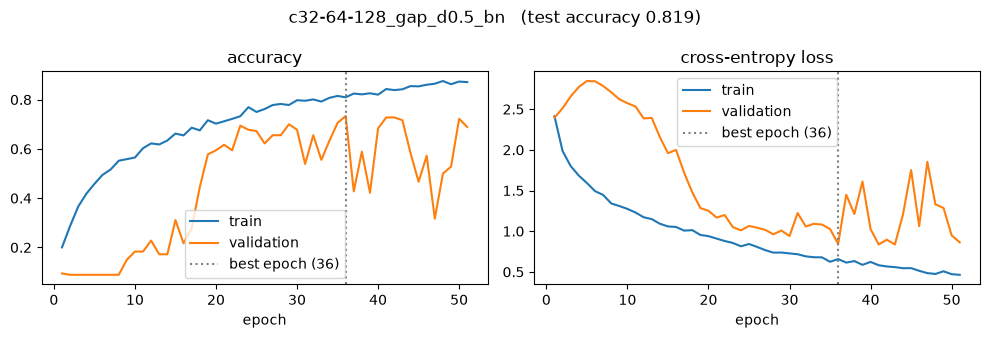

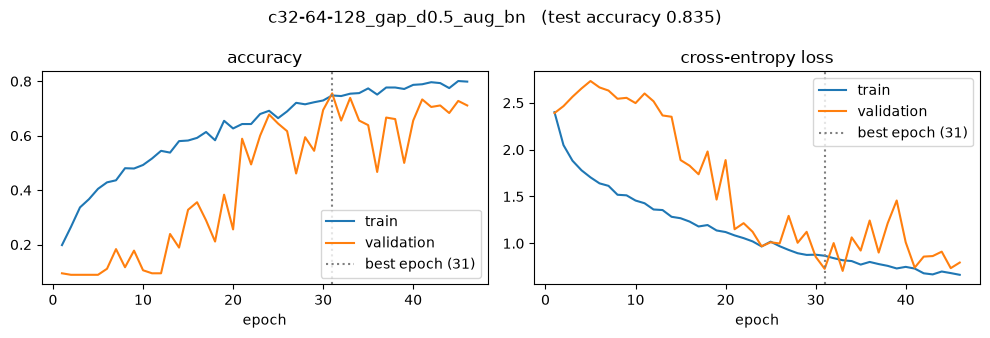

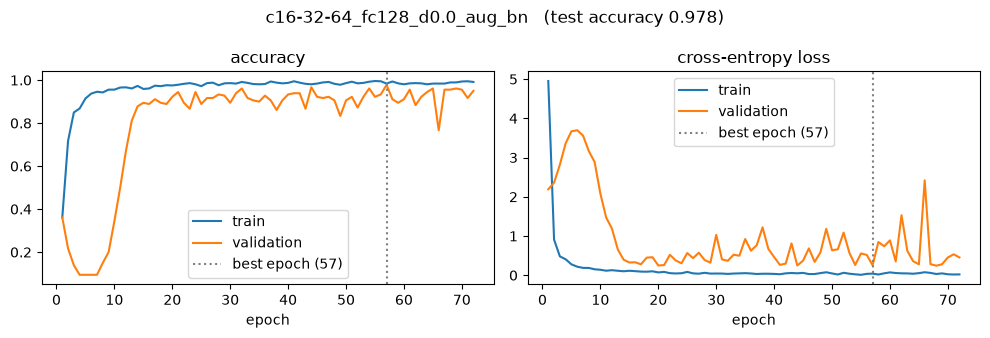

In [54]:
for r in extra_results:
    plot_run(r["name"])

**Observations extras:**

- `c32-64-128_gap_d0.5_aug`: with data augmentation the train and validation curves stay together for the whole run, so there is almost no overfitting anymore: every epoch the network sees slightly different letters, so it cannot memorise them. The validation accuracy goes up from 0.883 to 0.922 (test 0.973, the same). It was still improving at epoch 127 of 150, so it could probably go a bit higher with more epochs.

- `c32-64-128_gap_d0.5_bn` and `_aug_bn`: batch normalization made the GAP network worse (validation 0.733 / 0.756) and very unstable. For the first ~8-10 epochs the validation accuracy is ~0.09, which is guessing (1/11). The reason is that during prediction batch normalization does not use the statistics of the batch but a moving average over all training batches, which is updated slowly (momentum 0.99). With only ~29 batches per epoch, this average lags behind the weights that change quickly, so in the beginning the validation predictions are almost random and later they jump up and down. Batch normalization together with 50% dropout is also known to work badly, because dropout changes the variance of the values that batch normalization has learned.

- `c16-32-64_fc128_d0.0_aug_bn`: the same startup problem (validation ~0.09 in epochs 4-8), but after epoch ~15 the validation accuracy is between 0.90 and 0.96, much higher than the 0.86 without augmentation and batch normalization. The training accuracy is ~0.99, so the gap between train and validation is much smaller: augmentation fixed most of the overfitting of the Flatten network. This is the **best network** of all experiments: validation 0.978 (best epoch 57), test 0.978.

So data augmentation was the most useful technique, because the real problem was the small training set. Whether batch normalization helped on the Flatten network is tested in 4.1.

### 4.1 Control runs: augmentation only and batch normalization only

The best network got augmentation and batch normalization together. These two runs use the same architecture with only one of the two, to see which one caused the improvement.

c16-32-64_fc128_d0.0_aug       params=2,121,995  epochs= 31 (best  16)     82s  val_acc=0.961  test_acc=0.978
c16-32-64_fc128_d0.0_bn        params=2,122,331  epochs= 64 (best  49)    320s  val_acc=0.800  test_acc=0.874


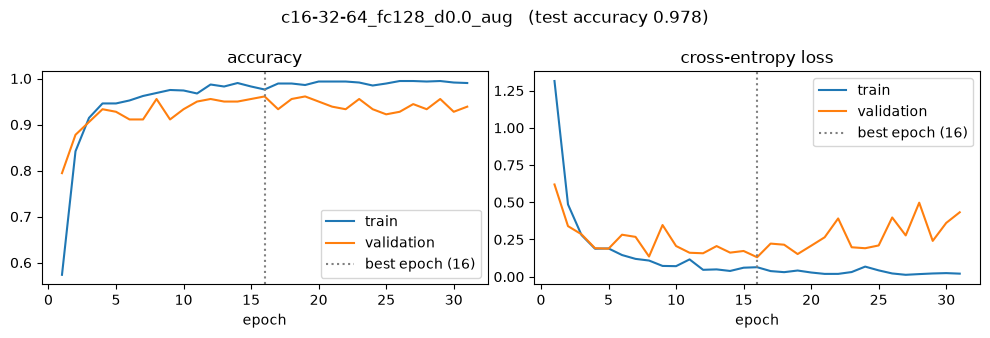

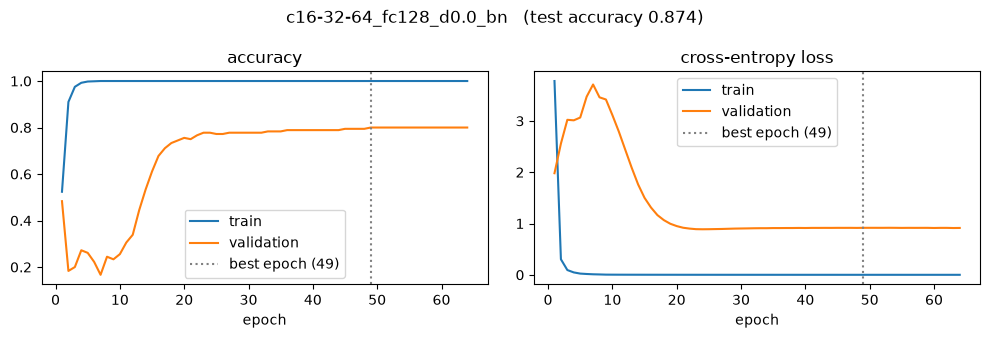

In [55]:
filters, dense, gap = ARCH["c16-32-64_fc128"]
controls = [run_experiment("c16-32-64_fc128_d0.0_aug", filters, dense, gap, 0.0, augment=True),
            run_experiment("c16-32-64_fc128_d0.0_bn",  filters, dense, gap, 0.0, batchnorm=True)]
for r in controls:
    plot_run(r["name"])

**Observations control runs:** With **augmentation only**, the network is already almost as good as with both: validation 0.961 (vs 0.978), test 0.978 (the same), and it is much more stable: the validation accuracy is above 0.9 from epoch 3 and it has the lowest validation loss of all networks (0.131). It also trains 7x faster (82 s vs 605 s). With **batch normalization only**, the network gets worse than without it (validation 0.800 vs 0.861), the first epochs are again close to guessing (0.17-0.27) and the training accuracy still goes to 1.0, so batch normalization alone does not stop the overfitting.

So the improvement from ~0.86 to ~0.97 comes from **data augmentation**. Batch normalization on top of augmentation adds 0.017 on validation (3 images) and nothing on the test set, which is within the noise of the small sets (see section 5).

In [56]:
summary()[["name", "params", "augment", "batchnorm", "epochs_run", "best_epoch", "val_acc", "val_loss", "test_acc"]]

,name,params,augment,batchnorm,epochs_run,best_epoch,val_acc,val_loss,test_acc
0,c16-32-64_fc128_d0.0_aug_bn,2122331,True,True,72,57,0.977778,0.255216,0.978022
1,c16-32-64_fc128_d0.0_aug,2121995,True,False,31,16,0.961111,0.130823,0.978022
2,c32-64-128_gap_d0.5_aug,94091,True,False,142,127,0.922222,0.298374,0.972527
3,c32-64-128_gap_d0.5,94091,False,False,114,99,0.883333,0.488993,0.972527
4,c32-64-128_gap_d0.3,94091,False,False,122,107,0.861111,0.546703,0.978022
5,c16-32-64_fc128_d0.0,2121995,False,False,19,4,0.861111,0.697045,0.857143
6,c32-64-128_fc128_d0.0,4288523,False,False,20,5,0.838889,0.890000,0.851648
7,c32-64_fc128_d0.5,8408971,False,False,36,21,0.838889,1.009914,0.851648
8,c32-64_fc128_d0.3,8408971,False,False,33,18,0.833333,1.053987,0.862637
9,c32-64-128_gap_d0.0,94091,False,False,92,77,0.827778,0.735559,0.912088


## 5. Cross-validation of the best network

The validation and test sets have only ~180 images each (1 image = ~0.55 percentage points), so differences of a few percent between networks can be noise. The best network (highest validation accuracy) is trained again with 5-fold cross-validation on train + validation, with the date/time stamps kept together (`StratifiedGroupKFold`). Each fold is trained for the same number of epochs as the best epoch of the original run and scored on the held-out fold. The test set is not used.

In [57]:
def cross_validate(cfg, k=5):
    idx = np.concatenate([train_idx, val_idx])
    scores = []
    splits = StratifiedGroupKFold(k, shuffle=True, random_state=SEED).split(np.zeros(len(idx)), y[idx], sessions[idx])
    
    for fold, (tr, va) in enumerate(splits, 1):
        keras.utils.set_random_seed(SEED + fold)
        model = build_cnn(cfg["filters"], cfg["dense"], cfg["dropout"], cfg["gap"], cfg.get("augment", False), cfg.get("batchnorm", False))
        model.fit(X[idx[tr]], to_categorical(y[idx[tr]], N_CLASSES), epochs=cfg["best_epoch"], batch_size=BATCH, verbose=0)
        scores.append(float(model.evaluate(X[idx[va]], to_categorical(y[idx[va]], N_CLASSES), verbose=0)[1]))
        print(f"fold {fold}: {len(va)} images, accuracy {scores[-1]:.3f}")
    
    return scores

best = json.loads((RESULTS / f"{summary().loc[0, 'name']}.json").read_text())
cv_path = Path("cv_result_cnn.json")                            # cached: the 5 folds take a while

if cv_path.exists() and json.loads(cv_path.read_text())["name"] == best["name"]:
    cv = json.loads(cv_path.read_text())
    for fold, s in enumerate(cv["scores"], 1): print(f"fold {fold}: accuracy {s:.3f}")
else:
    cv = dict(name=best["name"], scores=cross_validate(best))
    cv_path.write_text(json.dumps(cv))

print(f"network: {cv['name']}   mean {np.mean(cv['scores']):.3f} +/- {np.std(cv['scores']):.3f}   (validation {best['val_acc']:.3f}, test {best['test_acc']:.3f})")

fold 1: accuracy 0.946
fold 2: accuracy 0.917
fold 3: accuracy 0.973
fold 4: accuracy 0.973
fold 5: accuracy 0.950
network: c16-32-64_fc128_d0.0_aug_bn   mean 0.952 +/- 0.021   (validation 0.978, test 0.978)


**Observations cross-validation:** The cross-validation of c16-32-64_fc128_d0.0_aug_bn gives a mean accuracy of 0.952 +/- 0.021 over the 5 folds, so the network performs well on all parts of the data, not only on our validation and test set. The mean is a bit lower than the validation and test accuracy (both 0.978). That is expected: this network was chosen *because* it had the highest validation accuracy, so that score is a bit optimistic, and each fold also trains on fewer images. The folds go from 0.917 to 0.973, so a difference of ~5 percentage points can be caused only by which images are in the evaluation set. Differences between networks smaller than that (e.g. 0.861 vs 0.883 in section 3) are therefore not reliable; the jump from ~0.86-0.88 to 0.95-0.98 with augmentation is.

## 6. Evaluation of the best network per letter (test set)

c16-32-64_fc128_d0.0_aug_bn: test accuracy 0.978


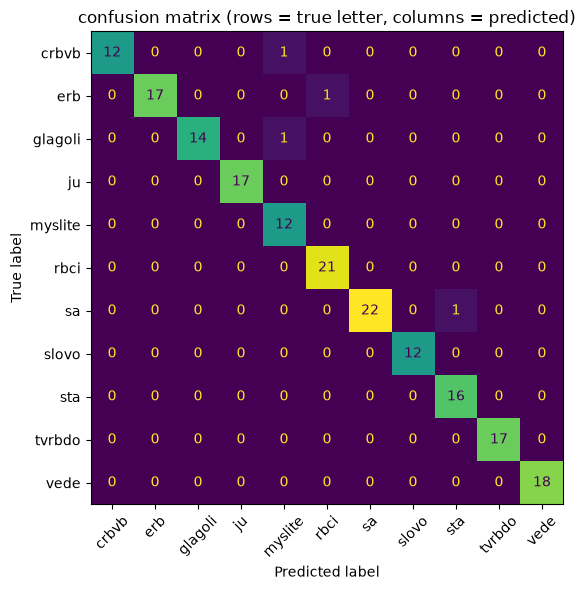

,crbvb,erb,glagoli,ju,myslite,rbci,sa,slovo,sta,tvrbdo,vede
test images,13.000,18.000,15.000,17.0,12.0,21.0,23.000,12.0,16.0,17.0,18.0
recall,0.923,0.944,0.933,1.0,1.0,1.0,0.957,1.0,1.0,1.0,1.0


In [58]:
best_model = keras.models.load_model(MODELS / f"{best['name']}.keras")
pred = best_model.predict(X_test, batch_size=64, verbose=0).argmax(1)
print(f"{best['name']}: test accuracy {(pred == y_test).mean():.3f}")

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=range(N_CLASSES)), display_labels=CLASSES).plot(ax=ax, colorbar=False, xticks_rotation=45)
ax.set_title("confusion matrix (rows = true letter, columns = predicted)"); 
plt.tight_layout(); 
plt.show()

pd.DataFrame({"test images": np.bincount(y_test, minlength=N_CLASSES),
              "recall": [round(float((pred[y_test == c] == c).mean()), 3) for c in range(N_CLASSES)]}, index=CLASSES).T

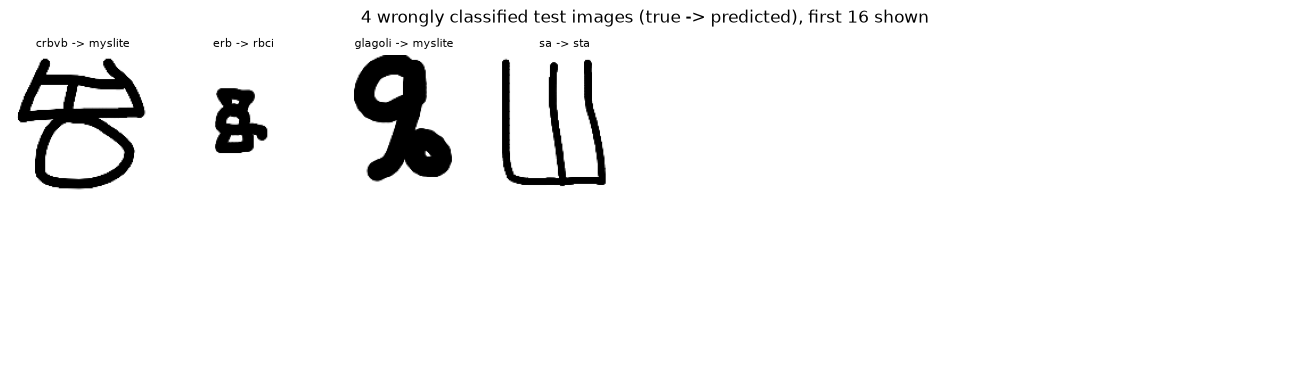

In [59]:
wrong = np.where(pred != y_test)[0]
fig, axes = plt.subplots(2, 8, figsize=(13, 3.8))

for a, i in zip(axes.flat, wrong):
    a.imshow(X_test[i, ..., 0], cmap="gray_r"); a.set_title(f"{CLASSES[y_test[i]]} -> {CLASSES[pred[i]]}", fontsize=8)

for a in axes.flat: a.axis("off")
fig.suptitle(f"{len(wrong)} wrongly classified test images (true -> predicted), first 16 shown"); 
plt.tight_layout(); 
plt.show()

**Observations per letter:** The best network gets only 4 of the 182 test images wrong (0.978). Seven letters are always correct; the lowest recall is crbvb (0.923), but that is 1 wrong image out of 13, so with 12-23 test images per letter one mistake already costs 4-8 percentage points. Looking at the wrong images:

- `erb -> rbci`: this letter is drawn very small compared to the other images. The augmentation only zooms up to 10%, so the network has not seen letters this small.
- `glagoli -> myslite`: drawn with a very thick line, so the small loops are almost filled in.
- `sa -> sta`: these two letters look alike (vertical strokes on a horizontal base), so this is an understandable mistake.
- `crbvb -> myslite`: the shape is drawn quite wide and open.

So the mistakes are mostly images that are drawn differently from the training images (size, line thickness), not one pair of letters that is always confused.

## 7. What does the network see?

The filters of the first convolutional layer, and the feature maps (outputs) of every convolutional layer for one test image.

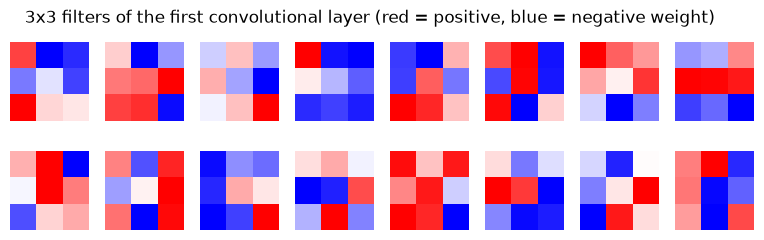

In [60]:
convs = [l for l in best_model.layers if isinstance(l, layers.Conv2D)]
w = convs[0].get_weights()[0]                                    # shape (3, 3, 1, number of filters)
fig, axes = plt.subplots(2, w.shape[-1] // 2, figsize=(w.shape[-1] * 0.6, 2.6))

for a, k in zip(axes.flat, range(w.shape[-1])):
    a.imshow(w[:, :, 0, k], cmap="bwr"); a.axis("off")

fig.suptitle("3x3 filters of the first convolutional layer (red = positive, blue = negative weight)"); 
plt.show()

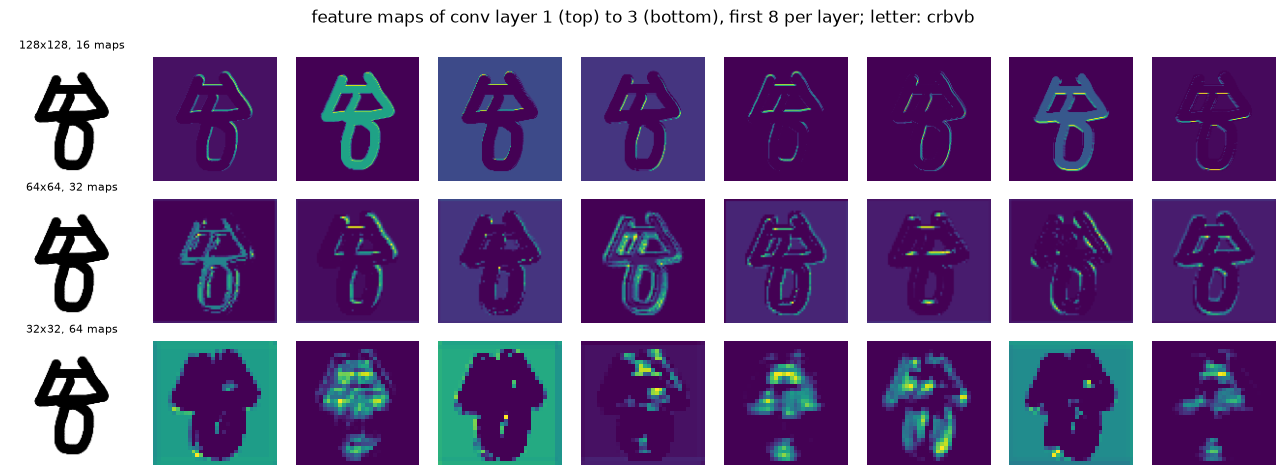

In [61]:
def feature_maps(model, image):
    """Run one image through the layers and keep the output just before every max-pooling (= after the ReLU)."""
    x, maps = image[None], []
    for layer, nxt in zip(model.layers, model.layers[1:] + [None]):
        x = layer(x, training=False)
        if isinstance(nxt, layers.MaxPooling2D):
            maps.append(np.asarray(x[0]))
    return maps

img = X_test[0]
maps = feature_maps(best_model, img)
fig, axes = plt.subplots(len(maps), 9, figsize=(13, 1.6 * len(maps)))
for row, m in zip(axes, maps):
    row[0].imshow(img[..., 0], cmap="gray_r"); row[0].set_title(f"{m.shape[0]}x{m.shape[1]}, {m.shape[2]} maps", fontsize=8)
    for a, k in zip(row[1:], range(8)):
        a.imshow(m[..., k], cmap="viridis")
    for a in row: a.axis("off")

fig.suptitle(f"feature maps of conv layer 1 (top) to {len(maps)} (bottom), first 8 per layer; letter: {CLASSES[y_test[0]]}"); 
plt.tight_layout(); 
plt.show()

**Observations visualisation:** The 3x3 filters of the first layer are mostly red on one side and blue on the other side, so they are **edge detectors** in different directions (horizontal, vertical, diagonal). This is visible in the feature maps of layer 1 (128x128): every map shows the letter, but highlights a different part, e.g. only the top edges, only the left edges, or the whole stroke. In layer 2 (64x64) the maps combine these edges into pieces of lines and corners in a certain direction. In layer 3 (32x32) the maps look less like the letter: they are coarse and "blobby" and react to bigger parts, like the top bar or the loop at the bottom, and some react to the background around the letter. So the deeper the layer, the more abstract and the less detailed the features become, which is how a CNN goes from pixels to the shape of a letter.

## 8. Export and reload of the best network

In [62]:
best_model.save("best_cnn_model.keras")
print("exported:", best["name"])

exported: c16-32-64_fc128_d0.0_aug_bn


In [63]:
# Load the exported model and evaluate it on images read from file (the test images listed in cnn_test_files.csv)
loaded = keras.models.load_model("best_cnn_model.keras")
test_files = pd.read_csv(TEST_FILE)
images = np.stack([load_image(IMAGE_DIR / f) for f in test_files["file"]])[..., None]
pred = loaded.predict(images, batch_size=64, verbose=0).argmax(1)
print(f"accuracy of the loaded model on {len(images)} images from {IMAGE_DIR}: {(pred == test_files['letter'].map(CLASSES.index)).mean():.3f}")

accuracy of the loaded model on 182 images from ..\data\letters: 0.978


## 9. Conclusion

The experiments show that for this small dataset (1,286 images, ~920 for training) the biggest problem was **overfitting**, and that regularization and data augmentation mattered more than the size of the network.

The networks with Flatten and a dense layer have 2-8 million weights, almost all in the dense layer, and memorised the training set within 3 epochs (training accuracy 1.0, validation 0.77-0.86). A third convolutional layer helped (0.861 vs 0.77), because it makes the image smaller before Flatten and combines simple features into bigger parts of the letter; more filters per layer did not help. Dropout improved the Flatten networks only a little (0.833-0.839).

The networks with global average pooling have 20-100x fewer weights (19k-94k), learn much slower and overfit much less. With only 2 convolutional layers the GAP network underfitted (0.650), but with 3 layers and dropout it was the best network of the grid (validation 0.883, test 0.973). For these networks the first version of early stopping (validation loss, maximum 40 epochs) stopped far too early; with early stopping on the validation accuracy they needed 77-122 epochs.

Data augmentation was the most effective technique: it removed most of the gap between training and validation. The control runs in 4.1 show that it caused almost all of the improvement (validation 0.861 -> 0.961 with augmentation only), while batch normalization alone made the network worse (0.800). The best network is `c16-32-64_fc128_d0.0_aug_bn` (3 convolutional layers, a dense layer of 128, data augmentation and batch normalization), with 0.978 validation and test accuracy and 0.952 +/- 0.021 in 5-fold cross-validation. It is the exported model; the network with augmentation only scores the same on the test set (0.978), trains 7x faster and is more stable, so it would be an equally good choice. Batch normalization was not an improvement on its own: on the GAP network with 50% dropout it made training unstable and the results worse (0.733), probably because its moving statistics need many updates and because batch normalization and dropout do not work well together.

All test images with the same date/time stamp were kept together, so the test score is not inflated by very similar images in train and test. The best network makes only 4 mistakes on 182 test images, mostly on letters that are drawn much smaller or with a thicker line than usual.

**Limitations and improvements:**

- The validation and test sets are small (~180 images, 1 image = 0.55%) and every network was trained with one seed only, so small differences between networks are noise; the cross-validation folds differ by up to 5 percentage points.
- Augmentation and batch normalization were only tested on two architectures, and `c32-64-128_gap_d0.5_aug` was still improving close to the 150-epoch limit.
- Possible improvements: a stronger zoom range in the augmentation (for very small letters), a lower batch-normalization momentum, a learning-rate schedule, or transfer learning from a network pretrained on handwritten characters.